# 02. Référence classique : CSP + LDA

**Pipeline :** filtrage 8-30 Hz (MOABB, sur le signal continu) puis, dans un `Pipeline` scikit-learn
réappris à chaque pli : CSP (log-puissance de 6 composantes en binaire, 8 en 4 classes) et LDA.
Fenêtre : 0,5 à 2,5 s après l'indice, fixée a priori.

**Évaluations :**
- intra-session : validation croisée stratifiée en 5 plis, dans chaque session ;
- inter-session : apprentissage sur la session 1, test sur la session 2 (protocole de la compétition).

**Niveau du hasard :** chaque évaluation est refaite 100 fois avec des étiquettes permutées.

Calculs : `src/phase2_csp_lda.py` (ce notebook ne fait que relire les résultats).

In [1]:
import os, sys
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RACINE); sys.path.insert(0, str(RACINE))
import pandas as pd
from IPython.display import Image, display

## 1. Résumé sur les 9 sujets (moyenne et écart-type entre sujets)

In [2]:
pd.read_csv("results/phase2_resume.csv").round(3)

,methode,tache,evaluation,accuracy_moyenne,accuracy_ecart_type,kappa_moyen,kappa_ecart_type,kappa_min,kappa_max,sujets_au_dessus_du_hasard
0,CSP+LDA,4classes,inter,0.624,0.172,0.499,0.229,0.144,0.745,9
1,CSP+LDA,4classes,intra,0.664,0.188,0.552,0.250,0.134,0.806,9
2,CSP+LDA,binaire,inter,0.786,0.166,0.571,0.331,0.111,0.944,8
3,CSP+LDA,binaire,intra,0.780,0.168,0.561,0.336,0.069,0.938,6


## 2. Scores par sujet

Barres : accuracy. Chiffre : kappa de Cohen, kappa = (accuracy observée - accuracy attendue par hasard)
/ (1 - accuracy attendue). Trait foncé : 95e centile des accuracies obtenues avec étiquettes permutées.
Une barre sous ce trait n'est pas distinguable du hasard.

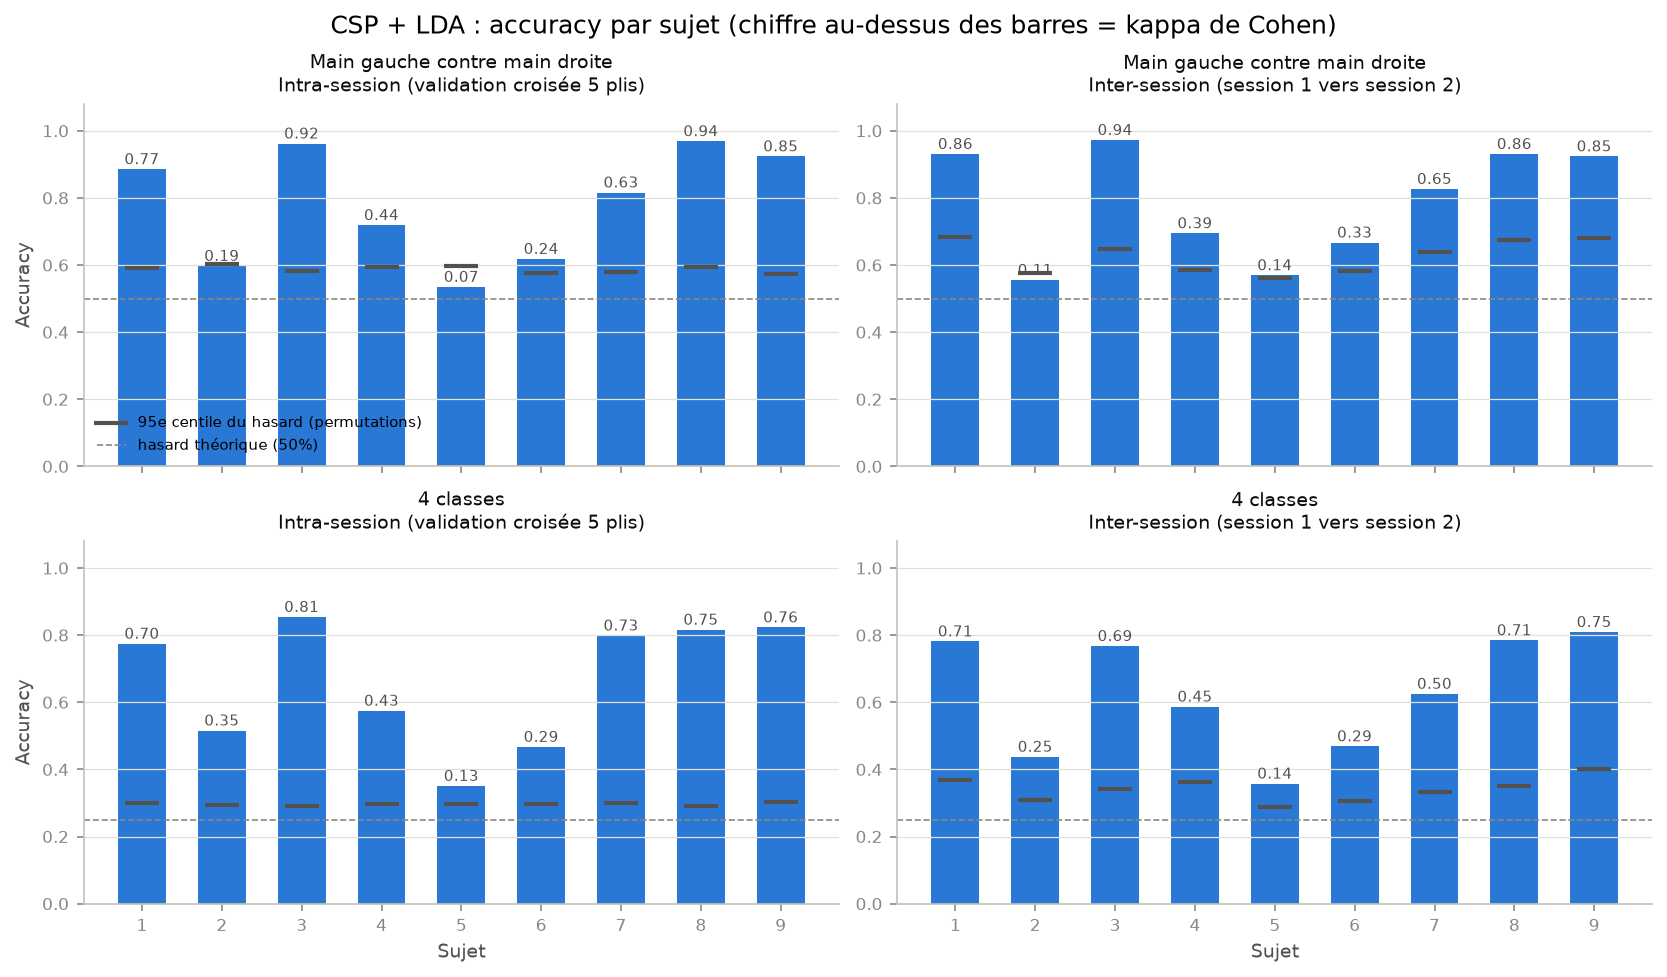

In [3]:
display(Image("reports/figures/phase2_scores_par_sujet.png"))

In [4]:
par_sujet = pd.read_csv("results/phase2_scores_par_sujet.csv")
par_sujet.pivot_table(index="sujet", columns=["tache", "evaluation"], values="kappa").round(3)

tache      4classes        binaire       
evaluation    inter  intra   inter  intra
sujet                                    
1             0.708  0.699   0.861  0.771
2             0.250  0.354   0.111  0.194
3             0.690  0.806   0.944  0.924
4             0.449  0.433   0.389  0.438
5             0.144  0.134   0.139  0.069
6             0.292  0.289   0.333  0.236
7             0.500  0.732   0.653  0.632
8             0.713  0.755   0.861  0.938
9             0.745  0.764   0.847  0.847

## 3. Niveau du hasard et p-valeurs

Avec 100 permutations, la plus petite p-valeur possible est 1/101, soit environ 0,0099.
Le seuil de hasard est plus élevé en inter-session : un seul ensemble de test, sans moyenne sur des plis,
donne une distribution de scores aléatoires plus étalée.

In [5]:
scores = pd.read_csv("results/phase2_scores.csv")
scores[scores["p_valeur"] >= 0.05][["sujet", "tache", "evaluation", "session", "accuracy",
                                    "hasard_accuracy_p95", "p_valeur"]]

,sujet,tache,evaluation,session,accuracy,hasard_accuracy_p95,p_valeur
3,2,binaire,intra,0train,0.6042,0.6111,0.0693
4,2,binaire,intra,1test,0.5903,0.5972,0.0693
5,2,binaire,inter,0train->1test,0.5556,0.5767,0.1386
12,5,binaire,intra,0train,0.4861,0.5906,0.6733
13,5,binaire,intra,1test,0.5833,0.6042,0.1188
16,6,binaire,intra,1test,0.5764,0.5837,0.0891


## 4. Matrices de confusion (4 classes, cumulées sur les 9 sujets)

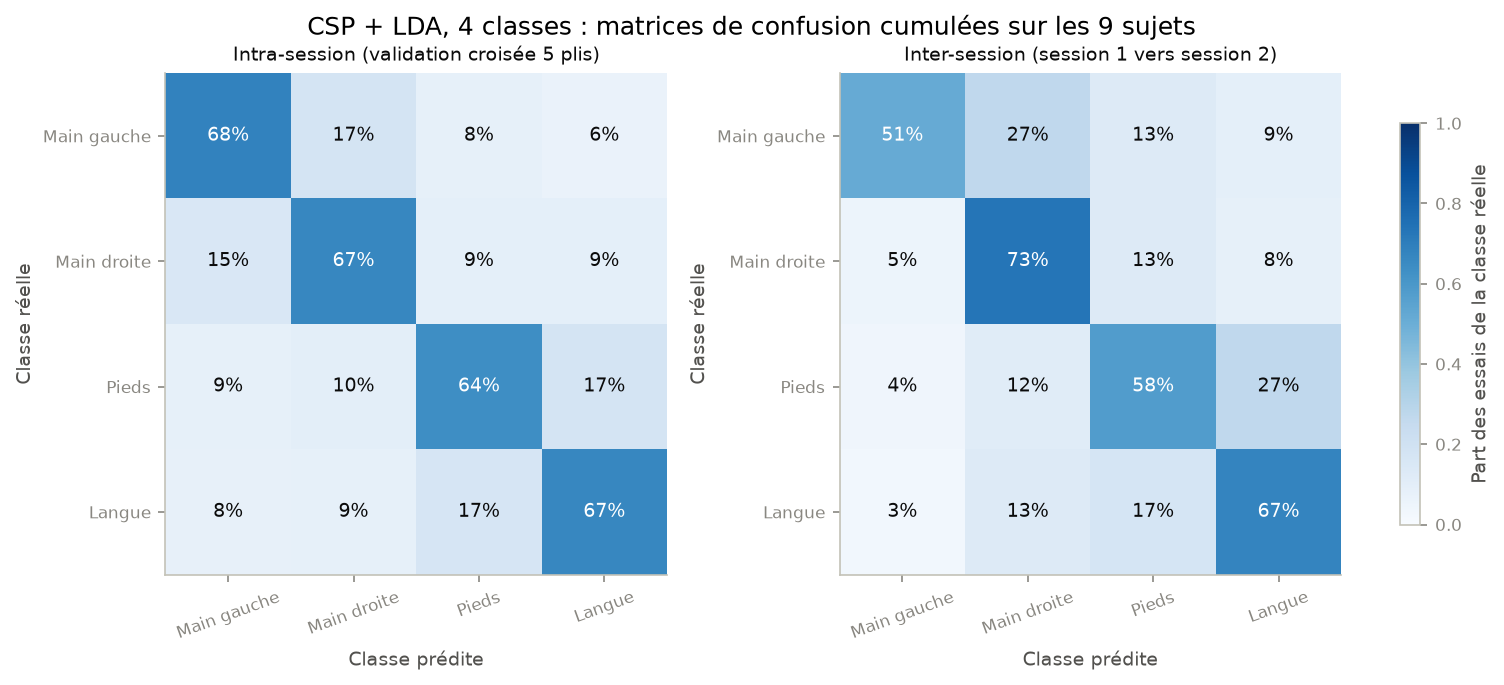

In [6]:
display(Image("reports/figures/phase2_confusion_4classes.png"))

## 5. Filtres et motifs CSP

- Un **filtre** est le jeu de poids appliqué aux 22 électrodes pour fabriquer une composante : c'est ce que
  le modèle *utilise*. Il annule aussi le bruit commun, d'où son aspect irrégulier, difficile à interpréter.
- Un **motif** (pattern) est la carte de la source que la composante capte, telle qu'elle se projette sur le scalp :
  c'est ce qu'il faut *interpréter* physiologiquement (Haufe et al., 2014).
- Le signe d'une composante est arbitraire : seule la forme de la carte compte.

Sujet 3 (meilleur en validation croisée sur la session 1), puis sujet 5 (le moins bon) et sujet 1.

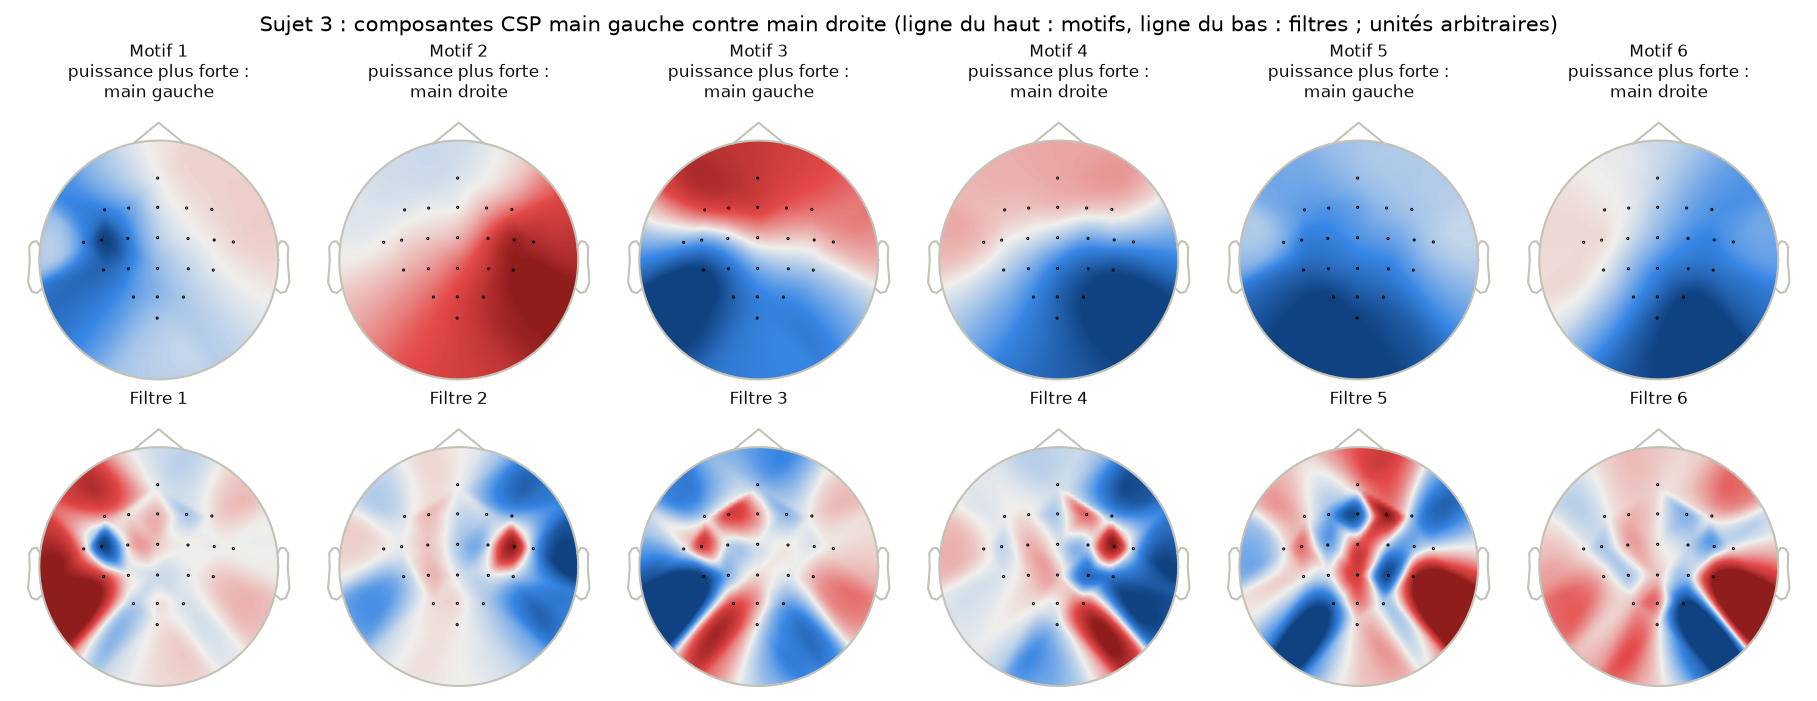

In [7]:
display(Image("reports/figures/phase2_csp_sujet03.png"))

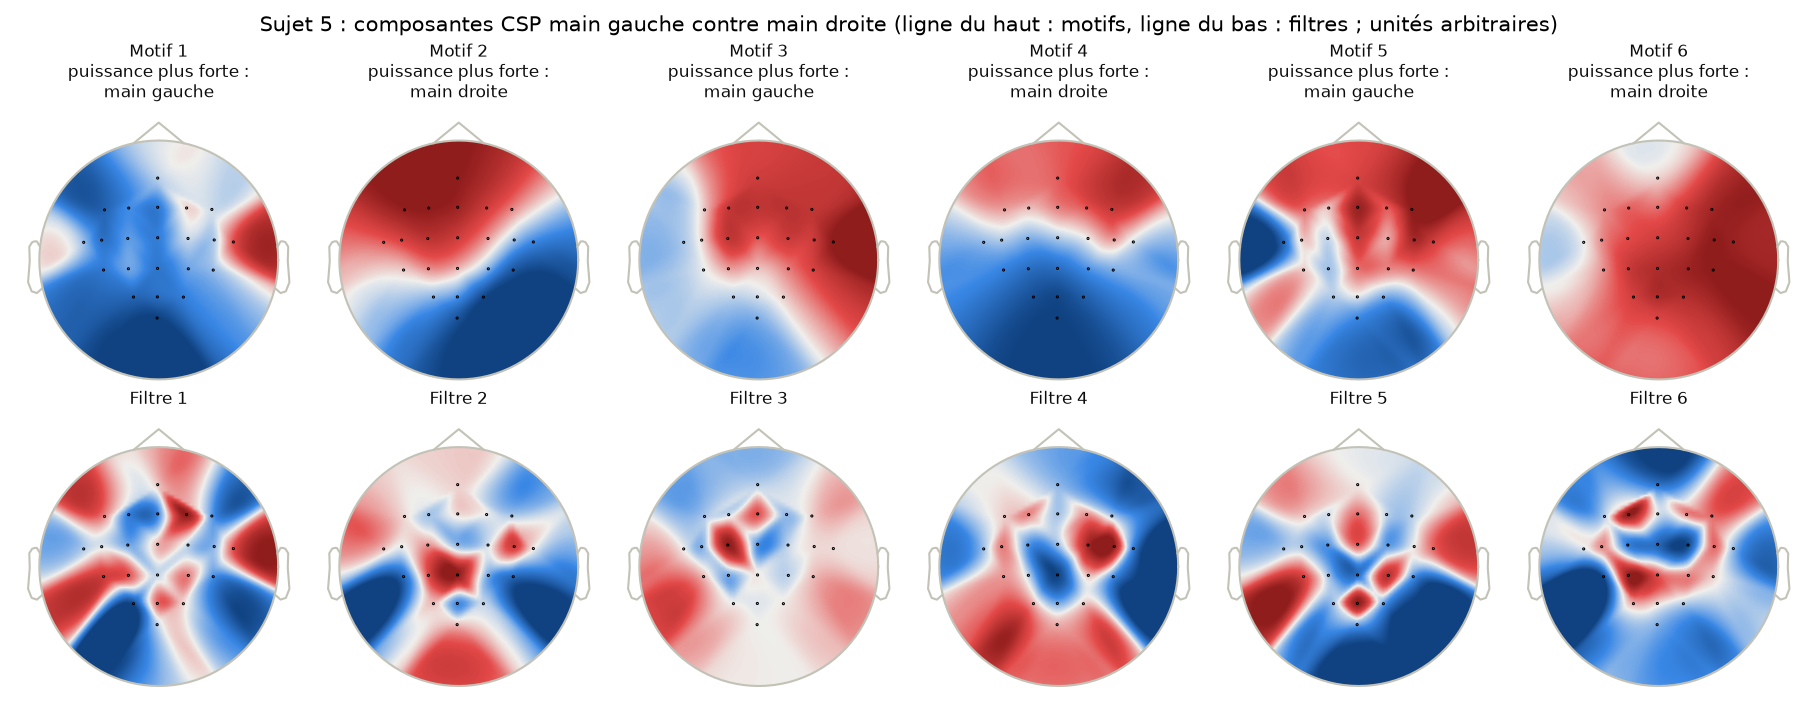

In [8]:
display(Image("reports/figures/phase2_csp_sujet05.png"))

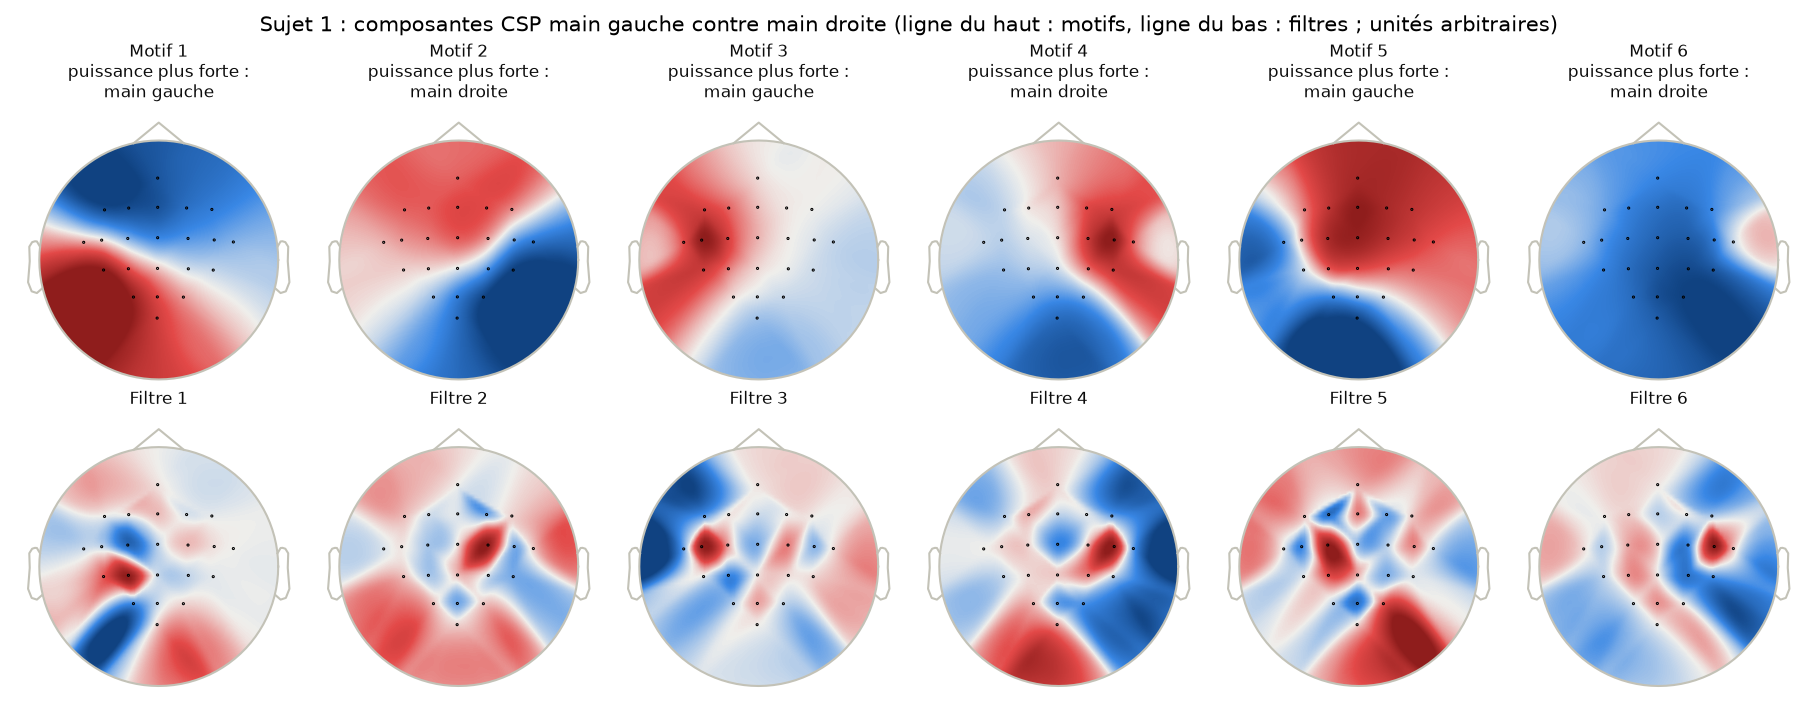

In [9]:
display(Image("reports/figures/phase2_csp_sujet01.png"))